In [1]:
import pandas as pd
import numpy as np 
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from imblearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("MentalHealthSurvey.csv")

In [3]:
df.shape

(87, 21)

In [4]:
df.dtypes

gender                      object
age                          int64
university                  object
degree_level                object
degree_major                object
academic_year               object
cgpa                        object
residential_status          object
campus_discrimination       object
sports_engagement           object
average_sleep               object
study_satisfaction           int64
academic_workload            int64
academic_pressure            int64
financial_concerns           int64
social_relationships         int64
depression                   int64
anxiety                      int64
isolation                    int64
future_insecurity            int64
stress_relief_activities    object
dtype: object

In [5]:
df.head()

,gender,age,university,degree_level,degree_major,academic_year,cgpa,residential_status,campus_discrimination,sports_engagement,...,study_satisfaction,academic_workload,academic_pressure,financial_concerns,social_relationships,depression,anxiety,isolation,future_insecurity,stress_relief_activities
0,Male,20,PU,Undergraduate,Data Science,2nd year,3.0-3.5,Off-Campus,No,No Sports,...,5,4,5,4,3,2,1,1,2,"Religious Activities, Social Connections, Onli..."
1,Male,20,UET,Postgraduate,Computer Science,3rd year,3.0-3.5,Off-Campus,No,1-3 times,...,5,4,4,1,3,3,3,3,4,Online Entertainment
2,Male,20,FAST,Undergraduate,Computer Science,3rd year,2.5-3.0,Off-Campus,No,1-3 times,...,5,5,5,3,4,2,3,3,1,"Religious Activities, Sports and Fitness, Onli..."
3,Male,20,UET,Undergraduate,Computer Science,3rd year,2.5-3.0,On-Campus,No,No Sports,...,3,5,4,4,1,5,5,5,3,Online Entertainment
4,Female,20,UET,Undergraduate,Computer Science,3rd year,3.0-3.5,Off-Campus,Yes,No Sports,...,3,5,5,2,3,5,5,4,4,Online Entertainment


In [6]:
object_columns=["gender", "university", "degree_level", "degree_major",
                "academic_year", "cgpa", "residential_status", 
                "campus_discrimination", "sports_engagement",
                "average_sleep", "stress_relief_activities" ]

baseline_df = df.drop(columns = object_columns)

In [7]:
baseline_df

,age,study_satisfaction,academic_workload,academic_pressure,financial_concerns,social_relationships,depression,anxiety,isolation,future_insecurity
0,20,5,4,5,4,3,2,1,1,2
1,20,5,4,4,1,3,3,3,3,4
2,20,5,5,5,3,4,2,3,3,1
3,20,3,5,4,4,1,5,5,5,3
4,20,3,5,5,2,3,5,5,4,4
...,...,...,...,...,...,...,...,...,...,...
82,22,4,3,1,4,4,2,3,1,2
83,22,5,5,5,5,1,5,5,5,5
84,21,5,4,2,4,3,1,2,1,1
85,22,3,3,3,3,2,3,4,4,5


In [8]:
kmeans = Pipeline(
    [ ("scale", StandardScaler()),
     ("cluster", KMeans(n_clusters=2, n_init=10, random_state=42))
    ]
)

kmeans_labels = kmeans.fit_predict(baseline_df)

In [9]:
kmeans_labels


array([1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0,
       0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1,
       1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
       1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1],
      dtype=int32)

In [10]:
clusters = kmeans.predict(baseline_df)

In [11]:
print(clusters)

[1 1 1 0 0 0 0 1 0 0 1 1 0 0 0 1 1 1 0 0 1 0 0 0 1 1 1 0 1 1 1 1 0 1 0 0 0
 1 0 0 1 0 1 1 1 1 0 0 0 1 1 0 1 0 0 1 0 0 1 1 1 1 0 1 0 0 1 1 0 1 0 1 0 0
 1 0 0 1 0 0 0 1 1 0 1 0 1]


In [12]:
profile = baseline_df.copy()

profile['cluster'] = kmeans_labels

In [13]:
print(profile.groupby("cluster").size())

cluster
0    44
1    43
dtype: int64


In [14]:
print(profile.groupby("cluster").mean())

               age  study_satisfaction  academic_workload   academic_pressure  \
cluster                                                                         
0        20.045455            3.636364            4.136364           4.113636   
1        19.837209            4.232558            3.627907           3.441860   

         financial_concerns  social_relationships  depression   anxiety  \
cluster                                                                   
0                  3.886364              2.159091    4.204545  4.181818   
1                  2.883721              3.418605    2.209302  2.232558   

         isolation  future_insecurity  
cluster                                
0         4.250000           3.659091  
1         2.209302           2.348837  


In [15]:
print(profile.groupby("cluster").std())

              age  study_satisfaction  academic_workload   academic_pressure  \
cluster                                                                        
0        1.928423            1.058540            0.734243           0.969678   
1        1.252241            0.947106            0.900351           1.181249   

         financial_concerns  social_relationships  depression   anxiety  \
cluster                                                                   
0                  1.315664              0.938658    0.823479  0.785707   
1                  1.313108              1.051814    1.036435  0.921624   

         isolation  future_insecurity  
cluster                                
0         0.866025           1.363020  
1         1.059158           1.066452  


In [16]:
from sklearn.metrics import silhouette_score 

scaled = kmeans.named_steps["scale"].transform(baseline_df)

In [17]:
silhouette_scores = [({
    "Model":"Kmeans","Silhouette Score": (silhouette_score(scaled, kmeans_labels).round(3))
})]

In [18]:
silhouette_scores

[{'Model': 'Kmeans', 'Silhouette Score': 0.212}]

# Gaussian Mixture

In [20]:
gauss = Pipeline(
    [ ("scale", StandardScaler()),
     ("cluster", GaussianMixture(
         n_components=2, n_init=5, random_state=42))
    ]
)

gauss_labels = gauss.fit_predict(baseline_df)

In [21]:
print(gauss_labels)

[0 1 0 1 0 1 1 0 0 1 0 0 1 1 0 0 0 0 0 1 0 1 0 1 1 0 0 1 1 0 0 0 1 0 1 1 1
 0 1 0 0 1 1 0 0 0 1 0 1 0 0 1 1 0 0 0 1 0 0 0 0 0 1 1 1 1 0 0 0 0 1 1 1 0
 0 1 0 0 1 1 0 0 0 1 0 1 0]


In [22]:
gauss_profile = baseline_df.copy()

gauss_profile['profile'] = gauss_labels

In [23]:
print(gauss_profile.groupby("profile").size())

profile
0    50
1    37
dtype: int64


In [24]:
print(gauss_profile.groupby("profile").mean())

               age  study_satisfaction  academic_workload   academic_pressure  \
profile                                                                         
0        19.960000            3.980000            3.900000           3.560000   
1        19.918919            3.864865            3.864865           4.081081   

         financial_concerns  social_relationships  depression   anxiety  \
profile                                                                   
0                  3.020000              3.140000    2.460000  2.460000   
1                  3.891892              2.297297    4.243243  4.243243   

         isolation  future_insecurity  
profile                                
0         2.440000           2.520000  
1         4.324324           3.675676  


In [25]:
print(gauss_profile.groupby("profile").std())

              age  study_satisfaction  academic_workload   academic_pressure  \
profile                                                                        
0        1.159873            0.999796            0.886405           1.197957   
1        2.113165            1.109609            0.821995           0.953892   

         financial_concerns  social_relationships  depression   anxiety  \
profile                                                                   
0                  1.347560              1.160753    1.198809  1.091900   
1                  1.328821              1.023742    0.796011  0.722857   

         isolation  future_insecurity  
profile                                
0         1.231558            1.16479  
1         0.747368            1.39551  


In [26]:
g_scaled = gauss.named_steps["scale"].transform(baseline_df)

(silhouette_score(g_scaled, gauss_labels).round(3))

0.146

In [27]:
gauss_silhouette_scores = (silhouette_score(g_scaled, gauss_labels).round(3))

In [28]:
silhouette_scores.append({"Model": "Gaussian Mixture","Silhouette Score": gauss_silhouette_scores})

In [29]:
silhouette_scores

[{'Model': 'Kmeans', 'Silhouette Score': 0.212},
 {'Model': 'Gaussian Mixture', 'Silhouette Score': 0.146}]

# Agglomerative Clustering

In [31]:
Aggie = Pipeline(
    [ ("scale", StandardScaler()),
     ("cluster", AgglomerativeClustering(
         n_clusters=2, linkage="ward"))
    ]
)

aggie_labels = Aggie.fit_predict(baseline_df)

In [32]:
agg_profile = baseline_df.copy()

agg_profile['Profile'] = aggie_labels

In [33]:
print(agg_profile.groupby("Profile").size())

Profile
0    65
1    22
dtype: int64


In [34]:
print(agg_profile.groupby("Profile").mean())

               age  study_satisfaction  academic_workload   academic_pressure  \
Profile                                                                         
0        19.784615            4.061538            3.661538           3.600000   
1        20.409091            3.545455            4.545455           4.318182   

         financial_concerns  social_relationships  depression   anxiety  \
Profile                                                                   
0                  3.153846              3.030769    2.692308  2.707692   
1                  4.090909              2.045455    4.772727  4.727273   

         isolation  future_insecurity  
Profile                                
0         2.815385           2.553846  
1         4.500000           4.363636  


In [35]:
print(agg_profile.groupby("Profile").std())

              age  study_satisfaction  academic_workload   academic_pressure  \
Profile                                                                        
0        1.256139            0.949949            0.834358           1.086853   
1        2.383656            1.223861            0.509647           1.086119   

         financial_concerns  social_relationships  depression   anxiety  \
Profile                                                                   
0                  1.383279              1.145224    1.158165  1.071259   
1                  1.230915              0.950051    0.428932  0.455842   

         isolation  future_insecurity  
Profile                                
0         1.321603           1.225137  
1         0.740013           0.847711  


In [36]:
agg_scaled = Aggie.named_steps["scale"].transform(baseline_df)

(silhouette_score(agg_scaled, aggie_labels).round(3))

0.197

In [37]:
aggie_silhouette_score = (silhouette_score(agg_scaled, aggie_labels).round(3))

silhouette_scores.append({"Model": "Agglomerative Clustering",
                          "Silhouette Score": aggie_silhouette_score})

# Scores

In [39]:
silhouette_scores

[{'Model': 'Kmeans', 'Silhouette Score': 0.212},
 {'Model': 'Gaussian Mixture', 'Silhouette Score': 0.146},
 {'Model': 'Agglomerative Clustering', 'Silhouette Score': 0.197}]

In [40]:
silhouette_scores_df = pd.DataFrame(silhouette_scores)

In [41]:
Cluster_Sized = pd.Series(
    [(44,43),(50,37),(65,22)],
    index=[0,1,2]
)

In [42]:
silhouette_scores_df["Cluster Sizes"] = Cluster_Sized

In [43]:
silhouette_scores_df

,Model,Silhouette Score,Cluster Sizes
0,Kmeans,0.212,"(44, 43)"
1,Gaussian Mixture,0.146,"(50, 37)"
2,Agglomerative Clustering,0.197,"(65, 22)"


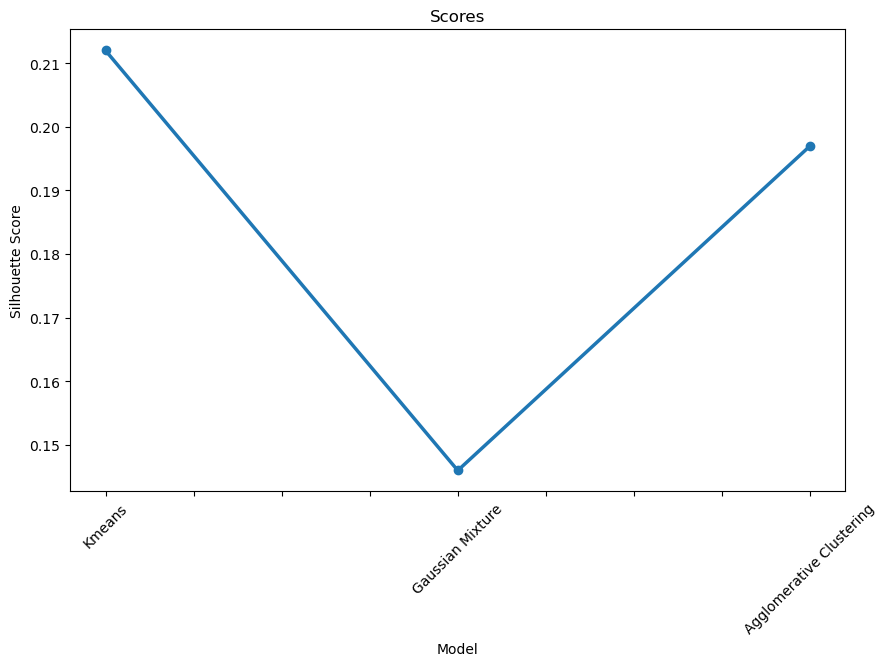

In [105]:
silhouette_scores_df.plot(x="Model", y="Silhouette Score", marker="o",
            title="Scores", rot=45, figsize=(10, 6), legend=False, linewidth=2.5)
plt.ylabel("Silhouette Score")
plt.savefig("baselines.png", bbox_inches="tight")
plt.show()
